# Assignment A_03 — K-Nearest Neighbors (KNN) Classifier from Scratch

**Dataset:** Wine Recognition Dataset (UCI)  
**Objective:** Classify each wine sample into one of three cultivar classes using its 13 chemical measurements.

This notebook implements the full workflow manually using **NumPy, Pandas, and Matplotlib**. It does not use a ready-made classifier, a distance utility, a feature scaler, or machine-learning evaluation functions.

### What this notebook does
1. Loads and explores the 178-row dataset.
2. Creates a stratified training/testing split, then manual stratified 5-fold cross-validation inside the training portion for choosing the configuration.
3. Implements raw, z-score, and min-max feature representations (scaling parameters are fitted on training data only).
4. Implements Euclidean and Manhattan distances, nearest-neighbor selection, majority voting, and a deterministic tie-break rule.
5. Compares `K = 1, 3, 5, 7, 9` across distance metrics, scaling approaches, and feature representations.
6. Evaluates the selected configuration once on the held-out test set, reports metrics and confusion matrix, and lists correct/incorrect predictions.
7. Answers all conceptual questions from the assignment.

> **Evaluation protocol:** The test set is held out until the configuration has been selected using stratified 5-fold cross-validation on the training portion. This avoids choosing `K` or preprocessing based on test-set performance.

## 1. Import permitted libraries and load the dataset

The Kaggle dataset should be added to the notebook before running. The loader searches `/kaggle/input` first and also checks the current working directory and `/mnt/data` (the latter is useful when running outside Kaggle). The uploaded `wine_clean.csv` has a header row and a `Class` target column.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the supplied CSV in Kaggle or a local execution environment.
search_roots = [Path('/kaggle/input'), Path.cwd(), Path('/mnt/data')]
csv_candidates = []
for root in search_roots:
    if root.exists():
        csv_candidates.extend(root.rglob('wine_clean.csv'))

# Remove duplicate paths while preserving the search order.
seen_paths = set()
csv_candidates = [p for p in csv_candidates if not (str(p.resolve()) in seen_paths or seen_paths.add(str(p.resolve())))]

if not csv_candidates:
    raise FileNotFoundError(
        "Could not find 'wine_clean.csv'. In Kaggle, use Add Input to attach the Wine dataset; "
        "otherwise place wine_clean.csv in the notebook's working directory."
    )

DATA_PATH = csv_candidates[0]
df = pd.read_csv(DATA_PATH)

# Clean column-name whitespace only; do not alter feature values.
df.columns = [str(col).strip() for col in df.columns]

if 'Class' not in df.columns:
    raise ValueError("Expected a target column named 'Class' in wine_clean.csv.")

feature_names = [col for col in df.columns if col != 'Class']
if len(feature_names) != 13:
    raise ValueError(f"Expected 13 input features, but found {len(feature_names)}: {feature_names}")

# Convert the feature matrix and target vector to NumPy arrays.
X = df[feature_names].to_numpy(dtype=float)
y = df['Class'].to_numpy()
row_ids = df.index.to_numpy()

print(f'Dataset path: {DATA_PATH}')
print(f'Dataset shape: {df.shape}')
print(f'Number of samples: {len(df)}')
print(f'Number of input features: {len(feature_names)}')
print(f'Target column: Class')
print('\nInput features:')
for i, name in enumerate(feature_names, start=1):
    print(f'{i:2d}. {name}')
print('\nTarget class counts:')
print(df['Class'].value_counts().sort_index().to_string())
print(f'\nMissing values in complete dataset: {int(df.isna().sum().sum())}')
print('\nFirst five rows:')
print(df.head().to_string(index=False))

Dataset path: /mnt/data/wine_clean.csv
Dataset shape: (178, 14)
Number of samples: 178
Number of input features: 13
Target column: Class

Input features:
 1. Alcohol
 2. Malic_Acid
 3. Ash
 4. Alcalinity_of_Ash
 5. Magnesium
 6. Total_Phenols
 7. Flavanoids
 8. Nonflavanoid_Phenols
 9. Proanthocyanins
10. Color_Intensity
11. Hue
12. OD280_OD315
13. Proline

Target class counts:
Class
1    59
2    71
3    48

Missing values in complete dataset: 0

First five rows:
 Class  Alcohol  Malic_Acid  Ash  Alcalinity_of_Ash  Magnesium  Total_Phenols  Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity  Hue  OD280_OD315  Proline
     1    14.23        1.71 2.43               15.6        127           2.80        3.06                  0.28             2.29             5.64 1.04         3.92     1065
     1    13.20        1.78 2.14               11.2        100           2.65        2.76                  0.26             1.28             4.38 1.05         3.40     1050
     1    13.

### Dataset overview

The target is `Class` and the other 13 columns are input features. The chemical measurements use different numerical ranges (for example, magnesium and proline are much larger in magnitude than hue), which makes feature scaling important for distance-based classification.

Descriptive statistics for the 13 input features:
       Alcohol  Malic_Acid      Ash  Alcalinity_of_Ash  Magnesium  Total_Phenols  Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity      Hue  OD280_OD315   Proline
count  178.000     178.000  178.000            178.000    178.000        178.000     178.000               178.000          178.000          178.000  178.000      178.000   178.000
mean    13.001       2.336    2.367             19.495     99.742          2.295       2.029                 0.362            1.591            5.058    0.957        2.612   746.893
std      0.812       1.117    0.274              3.340     14.282          0.626       0.999                 0.124            0.572            2.318    0.229        0.710   314.907
min     11.030       0.740    1.360             10.600     70.000          0.980       0.340                 0.130            0.410            1.280    0.480        1.270   278.000
25%     12.362       1.602    2.210          

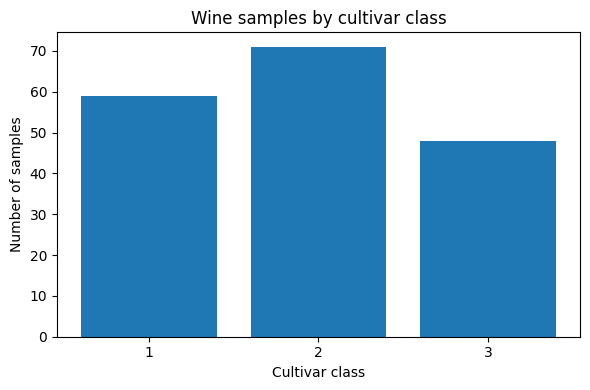

In [2]:
print('Descriptive statistics for the 13 input features:')
print(df[feature_names].describe().round(3).to_string())

class_counts = df['Class'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title('Wine samples by cultivar class')
plt.xlabel('Cultivar class')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()

## 2. Manual stratified training, validation, and testing split

First, 20% of each class is reserved for the final test set. The remaining 80% is the training pool. We compare configurations using manually implemented stratified 5-fold cross-validation within that training pool. No test rows are used in feature selection, scaling, or configuration selection.

The split and fold construction are implemented with NumPy only. Fixed random seeds make the experiment reproducible.

In [3]:
def stratified_split(X_values, y_values, ids, test_size=0.20, seed=42):
    """Manually split arrays while preserving each class's approximate proportion."""
    rng = np.random.default_rng(seed)
    train_indices = []
    test_indices = []

    for class_label in np.unique(y_values):
        class_indices = np.flatnonzero(y_values == class_label)
        rng.shuffle(class_indices)
        n_test = max(1, int(round(len(class_indices) * test_size)))
        test_indices.extend(class_indices[:n_test])
        train_indices.extend(class_indices[n_test:])

    train_indices = np.asarray(train_indices, dtype=int)
    test_indices = np.asarray(test_indices, dtype=int)
    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X_values[train_indices], y_values[train_indices], ids[train_indices],
        X_values[test_indices], y_values[test_indices], ids[test_indices]
    )


def stratified_kfold_indices(y_values, n_splits=5, seed=21):
    """Return manually generated stratified (train_indices, validation_indices) folds."""
    if n_splits < 2:
        raise ValueError('n_splits must be at least 2')
    rng = np.random.default_rng(seed)
    validation_folds = [[] for _ in range(n_splits)]

    for class_label in np.unique(y_values):
        class_indices = np.flatnonzero(y_values == class_label)
        rng.shuffle(class_indices)
        class_chunks = np.array_split(class_indices, n_splits)
        for fold_number, chunk in enumerate(class_chunks):
            validation_folds[fold_number].extend(chunk.tolist())

    all_indices = np.arange(len(y_values))
    folds = []
    for fold_number in range(n_splits):
        validation_indices = np.asarray(validation_folds[fold_number], dtype=int)
        rng.shuffle(validation_indices)
        train_indices = np.setdiff1d(all_indices, validation_indices, assume_unique=False)
        folds.append((train_indices, validation_indices))
    return folds


X_train_pool, y_train_pool, id_train_pool, X_test, y_test, id_test = stratified_split(
    X, y, row_ids, test_size=0.20, seed=42
)

cv_folds = stratified_kfold_indices(y_train_pool, n_splits=5, seed=21)

print(f'Total samples: {len(X)}')
print(f'Final training pool: {len(X_train_pool)}')
print(f'Final held-out test set: {len(X_test)}')
print(f'Number of cross-validation folds: {len(cv_folds)}')

split_summary = pd.DataFrame({
    'Complete dataset': pd.Series(y).value_counts().sort_index(),
    'Final training pool': pd.Series(y_train_pool).value_counts().sort_index(),
    'Test set': pd.Series(y_test).value_counts().sort_index(),
}).fillna(0).astype(int)
print('\nClass distribution across final splits:')
print(split_summary.to_string())

for fold_number, (fold_train_indices, fold_valid_indices) in enumerate(cv_folds, start=1):
    fold_counts = pd.Series(y_train_pool[fold_valid_indices]).value_counts().sort_index()
    print(f'Fold {fold_number}: train={len(fold_train_indices)}, validation={len(fold_valid_indices)}, '
          f'validation classes={fold_counts.to_dict()}')

Total samples: 178
Final training pool: 142
Final held-out test set: 36
Number of cross-validation folds: 5

Class distribution across final splits:
   Complete dataset  Final training pool  Test set
1                59                   47        12
2                71                   57        14
3                48                   38        10
Fold 1: train=112, validation=30, validation classes={1: 10, 2: 12, 3: 8}
Fold 2: train=112, validation=30, validation classes={1: 10, 2: 12, 3: 8}
Fold 3: train=114, validation=28, validation classes={1: 9, 2: 11, 3: 8}
Fold 4: train=115, validation=27, validation classes={1: 9, 2: 11, 3: 7}
Fold 5: train=115, validation=27, validation classes={1: 9, 2: 11, 3: 7}


## 3. Preprocessing implemented manually

Three scaling approaches are compared:

- **Raw:** no scaling.
- **Standardization (z-score):** subtract the fitting-set mean and divide by its population standard deviation.
- **Min-max scaling:** subtract the fitting-set minimum and divide by its range, mapping each non-constant feature to `[0, 1]`.

The functions below have separate `fit` and `transform` steps. In each cross-validation fold, means, standard deviations, minima, and maxima are calculated from that fold's training portion only, then reused unchanged for its validation fold. For final testing, they are refitted on the complete training pool and applied unchanged to the test data.

Two feature representations are compared:

- **All 13 features.**
- **Top 6 features:** chosen by a manually calculated Fisher score on each fold training portion only. The score compares between-class variation with within-class variation. It is recalculated from each fold's training portion and is never calculated using its validation fold or the final test set.

In [4]:
def fit_scaler(X_fit_values, method):
    """Calculate scaling parameters from fitting data only."""
    if method == 'raw':
        return {'method': 'raw'}
    if method == 'standard':
        mean = np.mean(X_fit_values, axis=0)
        std = np.std(X_fit_values, axis=0, ddof=0)
        std[std == 0] = 1.0
        return {'method': 'standard', 'mean': mean, 'scale': std}
    if method == 'minmax':
        minimum = np.min(X_fit_values, axis=0)
        maximum = np.max(X_fit_values, axis=0)
        span = maximum - minimum
        span[span == 0] = 1.0
        return {'method': 'minmax', 'minimum': minimum, 'scale': span}
    raise ValueError("method must be 'raw', 'standard', or 'minmax'")


def transform_with_scaler(X_values, scaler):
    """Apply previously fitted scaling parameters without refitting."""
    method = scaler['method']
    if method == 'raw':
        return X_values.astype(float, copy=True)
    if method == 'standard':
        return (X_values - scaler['mean']) / scaler['scale']
    if method == 'minmax':
        return (X_values - scaler['minimum']) / scaler['scale']
    raise ValueError(f'Unknown scaler method: {method}')


def calculate_fisher_scores(X_fit_values, y_fit_values):
    """Calculate one Fisher score per feature using fitting data only."""
    overall_mean = np.mean(X_fit_values, axis=0)
    between_class = np.zeros(X_fit_values.shape[1], dtype=float)
    within_class = np.zeros(X_fit_values.shape[1], dtype=float)

    for class_label in np.unique(y_fit_values):
        class_values = X_fit_values[y_fit_values == class_label]
        class_mean = np.mean(class_values, axis=0)
        between_class += len(class_values) * (class_mean - overall_mean) ** 2
        within_class += np.sum((class_values - class_mean) ** 2, axis=0)

    scores = np.divide(
        between_class,
        within_class,
        out=np.full_like(between_class, np.inf),
        where=within_class != 0
    )
    return scores


def select_feature_indices(X_fit_values, y_fit_values, feature_count=6):
    """Select top features by Fisher score; ties are resolved by original column order."""
    scores = calculate_fisher_scores(X_fit_values, y_fit_values)
    selected = np.argsort(-scores, kind='stable')[:feature_count]
    return selected, scores


scaling_methods = ['raw', 'standard', 'minmax']
feature_representations = ['all_13', 'top_6_fisher']

selected_fit_indices, fisher_scores_fit = select_feature_indices(X_train_pool, y_train_pool, feature_count=6)
fisher_table = pd.DataFrame({
    'Feature': feature_names,
    'Fisher score (training pool)': fisher_scores_fit
}).sort_values('Fisher score (training pool)', ascending=False)

print('Feature ranking calculated only from the final training pool (descriptive; selection is refitted within every CV fold):')
print(fisher_table.round(5).to_string(index=False))
print('\nSelected top 6 features:')
print([feature_names[i] for i in selected_fit_indices])

Feature ranking calculated only from the final training pool (descriptive; selection is refitted within every CV fold):
             Feature  Fisher score (training pool)
          Flavanoids                       2.63462
             Proline                       2.42038
         OD280_OD315                       2.23573
     Color_Intensity                       1.48019
             Alcohol                       1.45332
                 Hue                       1.05947
       Total_Phenols                       1.00607
   Alcalinity_of_Ash                       0.41875
     Proanthocyanins                       0.39408
          Malic_Acid                       0.33733
Nonflavanoid_Phenols                       0.26226
                 Ash                       0.12830
           Magnesium                       0.11354

Selected top 6 features:
['Flavanoids', 'Proline', 'OD280_OD315', 'Color_Intensity', 'Alcohol', 'Hue']


## 4. KNN algorithm implemented from scratch

For every query sample, the classifier calculates the distance to **every fitting sample**, sorts the distances, selects the nearest `K` samples, and predicts by majority vote.

- **Euclidean distance:** square root of the sum of squared feature differences.
- **Manhattan distance:** sum of the absolute feature differences.

**Vote-tie rule:** if two or more classes receive the same highest number of votes, choose the tied class with the smallest average distance among its selected neighbors. If that is still tied, choose the numerically smallest class label. This makes the result deterministic.

In [5]:
def euclidean_distance(point_a, point_b):
    """Euclidean distance calculated directly with NumPy arithmetic."""
    differences = point_a - point_b
    return float(np.sqrt(np.sum(differences * differences)))


def manhattan_distance(point_a, point_b):
    """Manhattan (L1) distance calculated directly with NumPy arithmetic."""
    return float(np.sum(np.abs(point_a - point_b)))


def calculate_distance(point_a, point_b, metric):
    if metric == 'euclidean':
        return euclidean_distance(point_a, point_b)
    if metric == 'manhattan':
        return manhattan_distance(point_a, point_b)
    raise ValueError("metric must be 'euclidean' or 'manhattan'")


def predict_one_knn(X_fit_values, y_fit_values, query_point, k, metric):
    """Predict one sample using a manual distance loop, sorting, and majority voting."""
    if k < 1 or k > len(X_fit_values):
        raise ValueError('K must be between 1 and the number of fitting samples.')

    distances = np.empty(len(X_fit_values), dtype=float)
    for index in range(len(X_fit_values)):
        distances[index] = calculate_distance(query_point, X_fit_values[index], metric)

    # Stable sorting gives a reproducible order if distances are exactly equal.
    neighbor_indices = np.argsort(distances, kind='stable')[:k]
    neighbor_labels = y_fit_values[neighbor_indices]
    neighbor_distances = distances[neighbor_indices]

    classes, vote_counts = np.unique(neighbor_labels, return_counts=True)
    highest_votes = np.max(vote_counts)
    tied_classes = classes[vote_counts == highest_votes]

    if len(tied_classes) == 1:
        prediction = tied_classes[0]
    else:
        # Tie-break 1: lowest mean distance among the tied classes.
        mean_distance_by_class = {}
        for class_label in tied_classes:
            mean_distance_by_class[class_label] = float(
                np.mean(neighbor_distances[neighbor_labels == class_label])
            )
        best_mean_distance = min(mean_distance_by_class.values())
        closest_tied_classes = [
            class_label for class_label, mean_distance in mean_distance_by_class.items()
            if np.isclose(mean_distance, best_mean_distance)
        ]
        # Tie-break 2: smallest label if mean distances are also tied.
        prediction = min(closest_tied_classes)

    return prediction, neighbor_indices, neighbor_distances


def knn_predict(X_fit_values, y_fit_values, X_query_values, k, metric):
    """Predict a collection of samples by repeatedly applying predict_one_knn."""
    predictions = np.empty(len(X_query_values), dtype=y_fit_values.dtype)
    for row in range(len(X_query_values)):
        predictions[row], _, _ = predict_one_knn(
            X_fit_values, y_fit_values, X_query_values[row], k, metric
        )
    return predictions


# A small manual check of the two distance functions and prediction routine.
point_a = np.array([1.0, 2.0, 3.0])
point_b = np.array([4.0, 6.0, 3.0])
print('Example Euclidean distance:', euclidean_distance(point_a, point_b))
print('Example Manhattan distance:', manhattan_distance(point_a, point_b))
example_prediction, example_neighbors, example_neighbor_distances = predict_one_knn(
    X_train_pool, y_train_pool, X_train_pool[0], k=3, metric='euclidean'
)
print('Example KNN prediction for the first fitting row:', example_prediction)
print('Neighbor indices within the fitting subset:', example_neighbors)
print('Distances to those neighbors:', np.round(example_neighbor_distances, 4))

Example Euclidean distance: 5.0
Example Manhattan distance: 7.0
Example KNN prediction for the first fitting row: 1
Neighbor indices within the fitting subset: [ 0 72 41]
Distances to those neighbors: [ 0.     10.3447 10.7227]


## 5. Evaluation metrics implemented manually

The confusion matrix uses **rows for actual classes** and **columns for predicted classes**. Precision, recall, and F1-score are calculated one class at a time from the confusion matrix. Macro averages give each class equal weight.

In [6]:
def make_confusion_matrix(y_true, y_pred, class_labels):
    """Construct a confusion matrix manually; rows=actual, columns=predicted."""
    matrix = np.zeros((len(class_labels), len(class_labels)), dtype=int)
    class_to_index = {label: index for index, label in enumerate(class_labels)}
    for actual, predicted in zip(y_true, y_pred):
        matrix[class_to_index[actual], class_to_index[predicted]] += 1
    return matrix


def metrics_from_predictions(y_true, y_pred, class_labels):
    """Calculate accuracy, class-wise precision/recall/F1, and macro averages manually."""
    matrix = make_confusion_matrix(y_true, y_pred, class_labels)
    total = np.sum(matrix)
    accuracy = float(np.trace(matrix) / total) if total else 0.0

    rows = []
    for index, class_label in enumerate(class_labels):
        true_positive = matrix[index, index]
        false_positive = np.sum(matrix[:, index]) - true_positive
        false_negative = np.sum(matrix[index, :]) - true_positive

        precision_denominator = true_positive + false_positive
        recall_denominator = true_positive + false_negative
        precision = true_positive / precision_denominator if precision_denominator else 0.0
        recall = true_positive / recall_denominator if recall_denominator else 0.0
        f1_denominator = precision + recall
        f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

        rows.append({
            'Class': class_label,
            'Precision': precision,
            'Recall': recall,
            'F1-score': f1,
            'Support': int(np.sum(matrix[index, :]))
        })

    per_class = pd.DataFrame(rows)
    macro = {
        'accuracy': accuracy,
        'macro_precision': float(per_class['Precision'].mean()),
        'macro_recall': float(per_class['Recall'].mean()),
        'macro_f1': float(per_class['F1-score'].mean())
    }
    return matrix, per_class, macro


# Verify metric calculations using a tiny hand-checkable example.
_check_true = np.array([1, 1, 2, 2])
_check_pred = np.array([1, 2, 2, 2])
_check_matrix, _check_per_class, _check_macro = metrics_from_predictions(
    _check_true, _check_pred, np.array([1, 2])
)
print('Manual metric check — confusion matrix:')
print(_check_matrix)
print('Manual metric check — accuracy:', round(_check_macro['accuracy'], 3))

Manual metric check — confusion matrix:
[[1 1]
 [0 2]]
Manual metric check — accuracy: 0.75


## 6. Compare K, distance metrics, scaling, and feature representations

The experiment grid tests each configuration using manually implemented stratified 5-fold cross-validation on the training pool:

- `K = 1, 3, 5, 7, 9`
- Euclidean and Manhattan distance
- Raw, standard, and min-max scaling
- All 13 features and the top 6 Fisher-ranked features

For every fold, each configuration is trained on four folds and evaluated on the remaining fold. The top-6 feature ranking and scaling parameters are recalculated using only that fold's training portion. The reported scores are averages across the five validation folds.

In [7]:
k_values = [1, 3, 5, 7, 9]
distance_metrics = ['euclidean', 'manhattan']
experiment_rows = []

for representation in feature_representations:
    for scaling_method in scaling_methods:
        for metric in distance_metrics:
            for k in k_values:
                fold_accuracies = []
                fold_macro_f1 = []

                for fold_train_indices, fold_valid_indices in cv_folds:
                    X_fold_train = X_train_pool[fold_train_indices]
                    y_fold_train = y_train_pool[fold_train_indices]
                    X_fold_valid = X_train_pool[fold_valid_indices]
                    y_fold_valid = y_train_pool[fold_valid_indices]

                    if representation == 'all_13':
                        feature_indices = np.arange(len(feature_names))
                    else:
                        feature_indices, _ = select_feature_indices(
                            X_fold_train, y_fold_train, feature_count=6
                        )

                    X_fold_train_selected = X_fold_train[:, feature_indices]
                    X_fold_valid_selected = X_fold_valid[:, feature_indices]
                    scaler = fit_scaler(X_fold_train_selected, scaling_method)
                    X_fold_train_transformed = transform_with_scaler(X_fold_train_selected, scaler)
                    X_fold_valid_transformed = transform_with_scaler(X_fold_valid_selected, scaler)

                    fold_predictions = knn_predict(
                        X_fold_train_transformed, y_fold_train,
                        X_fold_valid_transformed, k, metric
                    )
                    _, _, fold_metrics = metrics_from_predictions(
                        y_fold_valid, fold_predictions, np.unique(y)
                    )
                    fold_accuracies.append(fold_metrics['accuracy'])
                    fold_macro_f1.append(fold_metrics['macro_f1'])

                experiment_rows.append({
                    'Representation': representation,
                    'Scaling': scaling_method,
                    'Distance': metric,
                    'K': k,
                    'Mean CV accuracy': float(np.mean(fold_accuracies)),
                    'Std CV accuracy': float(np.std(fold_accuracies, ddof=0)),
                    'Mean CV macro-F1': float(np.mean(fold_macro_f1))
                })

results = pd.DataFrame(experiment_rows)
results = results.sort_values(
    ['Mean CV accuracy', 'Mean CV macro-F1', 'Std CV accuracy', 'K'],
    ascending=[False, False, True, True],
    kind='stable'
).reset_index(drop=True)

print(f'Total configurations tested: {len(results)}')
print(f'Each configuration was evaluated over {len(cv_folds)} stratified folds.')
print('\nTop 15 configurations by mean CV accuracy, then mean macro-F1:')
print(results.head(15).round(4).to_string(index=False))

best_row = results.iloc[0]
best_config = {
    'representation': best_row['Representation'],
    'scaling': best_row['Scaling'],
    'metric': best_row['Distance'],
    'k': int(best_row['K'])
}
print('\nSelected configuration (chosen using cross-validation results only):')
print(best_config)

Total configurations tested: 60
Each configuration was evaluated over 5 stratified folds.

Top 15 configurations by mean CV accuracy, then mean macro-F1:
Representation  Scaling  Distance  K  Mean CV accuracy  Std CV accuracy  Mean CV macro-F1
        all_13 standard manhattan  7            0.9933           0.0133            0.9939
        all_13   minmax euclidean  3            0.9867           0.0267            0.9868
        all_13 standard euclidean  3            0.9862           0.0169            0.9872
        all_13   minmax manhattan  7            0.9862           0.0169            0.9872
        all_13   minmax manhattan  1            0.9852           0.0296            0.9867
        all_13 standard euclidean  7            0.9795           0.0269            0.9802
        all_13 standard manhattan  5            0.9793           0.0271            0.9802
        all_13 standard euclidean  5            0.9790           0.0283            0.9798
        all_13 standard manhattan  1

## 7. Visualization and comparison

The first two plots show selected feature pairs with points colored by cultivar class. These are exploratory plots using the dataset values; they are not used to fit or select the model.

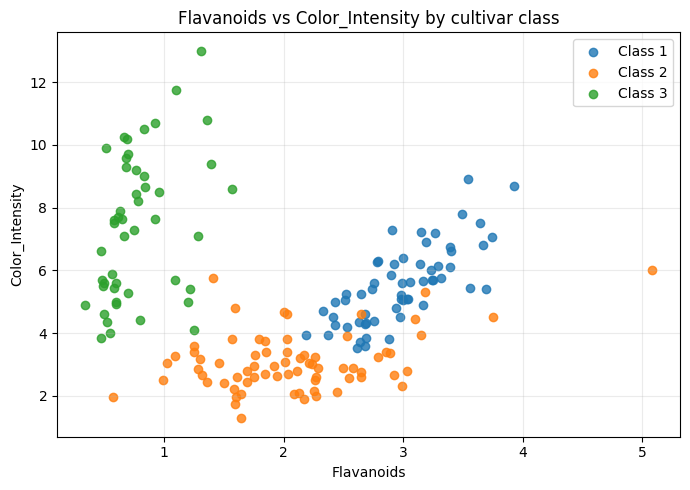

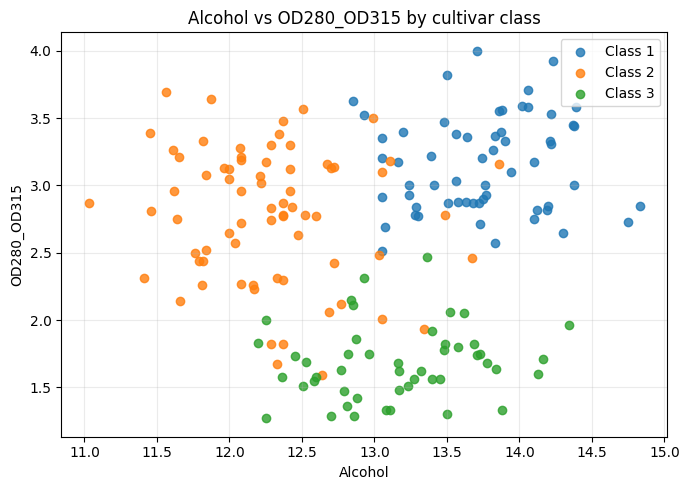

In [8]:
feature_pairs = [
    ('Flavanoids', 'Color_Intensity'),
    ('Alcohol', 'OD280_OD315')
]
class_labels = np.unique(y)

for x_feature, y_feature in feature_pairs:
    x_index = feature_names.index(x_feature)
    y_index = feature_names.index(y_feature)
    plt.figure(figsize=(7, 5))
    for class_label in class_labels:
        mask = y == class_label
        plt.scatter(
            X[mask, x_index], X[mask, y_index],
            label=f'Class {class_label}', alpha=0.8
        )
    plt.title(f'{x_feature} vs {y_feature} by cultivar class')
    plt.xlabel(x_feature)
    plt.ylabel(y_feature)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

### K versus cross-validation accuracy

The following chart compares both distance metrics across the three scaling methods using all 13 features. Mean cross-validation accuracy is shown because it is used for configuration selection; the final test set remains untouched at this stage.

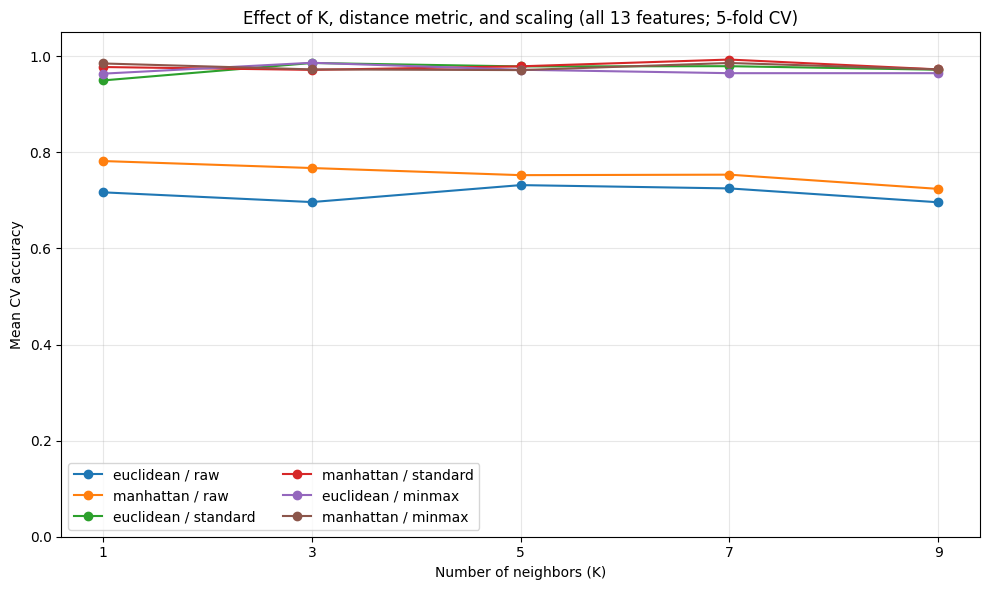

In [9]:
all_feature_results = results[results['Representation'] == 'all_13']
plt.figure(figsize=(10, 6))
for scaling_method in scaling_methods:
    for metric in distance_metrics:
        subset = all_feature_results[
            (all_feature_results['Scaling'] == scaling_method) &
            (all_feature_results['Distance'] == metric)
        ].sort_values('K')
        plt.plot(
            subset['K'], subset['Mean CV accuracy'],
            marker='o', label=f'{metric} / {scaling_method}'
        )
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.xlabel('Number of neighbors (K)')
plt.ylabel('Mean CV accuracy')
plt.title('Effect of K, distance metric, and scaling (all 13 features; 5-fold CV)')
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

### Comparing scaling and feature representations

This table averages cross-validation accuracy across the five tested `K` values for each representation, scaling method, and distance metric. It helps show the broader pattern rather than relying on one value of `K`.

Representation  Scaling  Distance  Mean CV accuracy  Best CV accuracy  Mean CV macro-F1
        all_13 standard manhattan            0.9790            0.9933            0.9803
        all_13   minmax manhattan            0.9777            0.9862            0.9788
        all_13 standard euclidean            0.9734            0.9862            0.9748
        all_13   minmax euclidean            0.9705            0.9867            0.9715
  top_6_fisher standard euclidean            0.9594            0.9654            0.9616
  top_6_fisher   minmax manhattan            0.9591            0.9647            0.9612
  top_6_fisher standard manhattan            0.9589            0.9647            0.9612
  top_6_fisher   minmax euclidean            0.9579            0.9654            0.9599
  top_6_fisher      raw manhattan            0.7564            0.7883            0.7435
        all_13      raw manhattan            0.7560            0.7821            0.7446
  top_6_fisher      raw euclidea

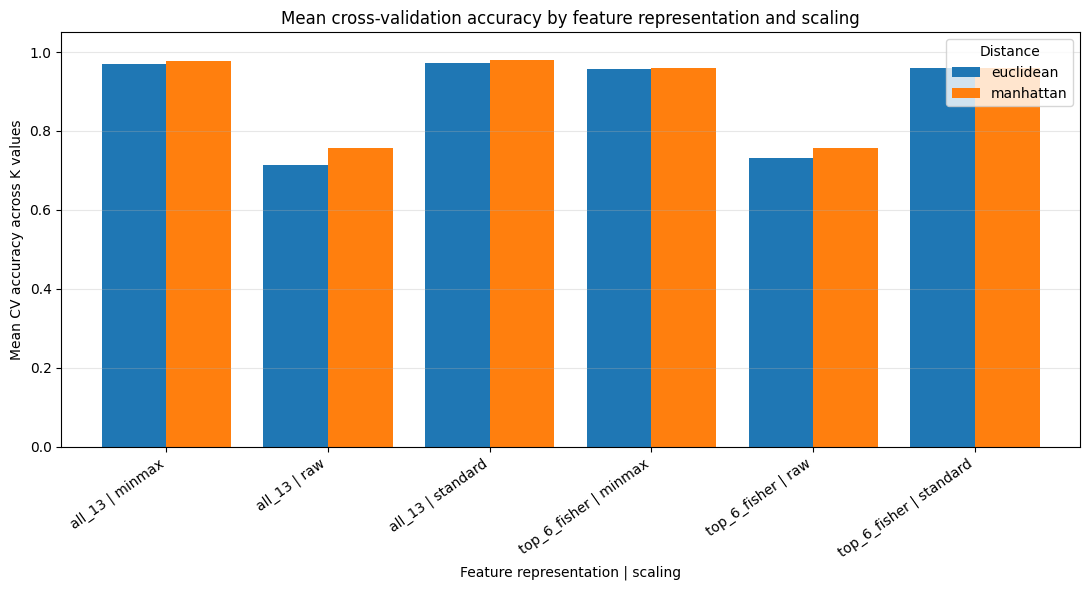

In [10]:
comparison = (
    results.groupby(['Representation', 'Scaling', 'Distance'], as_index=False)
    .agg(
        **{
            'Mean CV accuracy': ('Mean CV accuracy', 'mean'),
            'Best CV accuracy': ('Mean CV accuracy', 'max'),
            'Mean CV macro-F1': ('Mean CV macro-F1', 'mean')
        }
    )
    .sort_values('Mean CV accuracy', ascending=False)
)
print(comparison.round(4).to_string(index=False))

# Grouped bar chart: mean cross-validation accuracy by feature/scaling setup.
comparison['Setup'] = comparison['Representation'] + ' | ' + comparison['Scaling']
pivot_accuracy = comparison.pivot(index='Setup', columns='Distance', values='Mean CV accuracy')
ax = pivot_accuracy.plot(kind='bar', figsize=(11, 6), width=0.8)
ax.set_title('Mean cross-validation accuracy by feature representation and scaling')
ax.set_xlabel('Feature representation | scaling')
ax.set_ylabel('Mean CV accuracy across K values')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 8. Fit the selected configuration on the complete training pool and evaluate on the test set

After selecting the configuration using cross-validation results, the preprocessing and feature selection are fitted again using the **complete training pool**. The final test set is transformed using those same training-only parameters and is evaluated once.

In [11]:
def prepare_train_and_other(X_fit_values, y_fit_values, X_other_values,
                            feature_names, representation, scaling_method):
    """Fit feature representation and scaler on fitting data, then transform other data."""
    if representation == 'all_13':
        feature_indices = np.arange(X_fit_values.shape[1])
    elif representation == 'top_6_fisher':
        feature_indices, _ = select_feature_indices(
            X_fit_values, y_fit_values, feature_count=6
        )
    else:
        raise ValueError('Unknown feature representation')

    X_fit_selected = X_fit_values[:, feature_indices]
    X_other_selected = X_other_values[:, feature_indices]
    scaler = fit_scaler(X_fit_selected, scaling_method)
    X_fit_final = transform_with_scaler(X_fit_selected, scaler)
    X_other_final = transform_with_scaler(X_other_selected, scaler)
    selected_names = [feature_names[i] for i in feature_indices]
    return X_fit_final, X_other_final, selected_names, feature_indices, scaler


X_train_final, X_test_final, final_feature_names, final_feature_indices, final_scaler = prepare_train_and_other(
    X_train_pool, y_train_pool, X_test,
    feature_names, best_config['representation'], best_config['scaling']
)

final_predictions = knn_predict(
    X_train_final, y_train_pool, X_test_final,
    best_config['k'], best_config['metric']
)

final_matrix, final_per_class, final_metrics = metrics_from_predictions(
    y_test, final_predictions, class_labels
)

print('Final selected configuration:')
print(f"  K: {best_config['k']}")
print(f"  Distance: {best_config['metric']}")
print(f"  Scaling: {best_config['scaling']}")
print(f"  Representation: {best_config['representation']}")
print(f"  Features used ({len(final_feature_names)}): {final_feature_names}")
print('\nFinal held-out test metrics:')
print(f"  Accuracy:          {final_metrics['accuracy']:.4f}")
print(f"  Macro precision:   {final_metrics['macro_precision']:.4f}")
print(f"  Macro recall:      {final_metrics['macro_recall']:.4f}")
print(f"  Macro F1-score:    {final_metrics['macro_f1']:.4f}")
print('\nClass-wise test metrics:')
print(final_per_class.round(4).to_string(index=False))

Final selected configuration:
  K: 7
  Distance: manhattan
  Scaling: standard
  Representation: all_13
  Features used (13): ['Alcohol', 'Malic_Acid', 'Ash', 'Alcalinity_of_Ash', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280_OD315', 'Proline']

Final held-out test metrics:
  Accuracy:          0.9444
  Macro precision:   0.9441
  Macro recall:      0.9524
  Macro F1-score:    0.9452

Class-wise test metrics:
 Class  Precision  Recall  F1-score  Support
     1     0.9231  1.0000    0.9600       12
     2     1.0000  0.8571    0.9231       14
     3     0.9091  1.0000    0.9524       10


### Confusion matrix

Rows represent the actual cultivar and columns represent the predicted cultivar. Diagonal values are correct predictions; off-diagonal values are misclassifications.

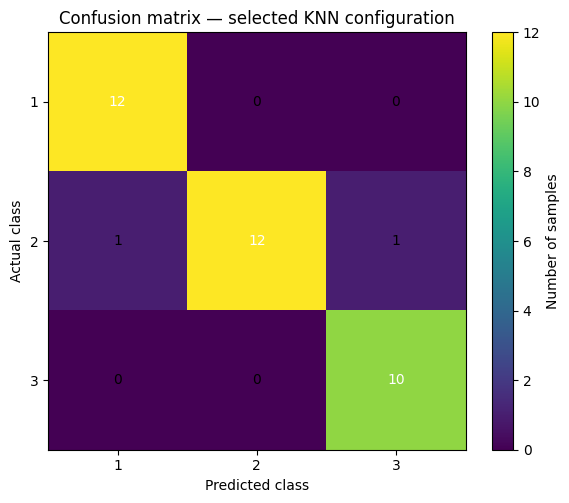

In [12]:
plt.figure(figsize=(6, 5))
image = plt.imshow(final_matrix, interpolation='nearest')
plt.title('Confusion matrix — selected KNN configuration')
plt.colorbar(image, label='Number of samples')
plt.xticks(np.arange(len(class_labels)), class_labels)
plt.yticks(np.arange(len(class_labels)), class_labels)
plt.xlabel('Predicted class')
plt.ylabel('Actual class')

threshold = final_matrix.max() / 2 if final_matrix.size else 0
for row in range(final_matrix.shape[0]):
    for column in range(final_matrix.shape[1]):
        plt.text(
            column, row, str(final_matrix[row, column]),
            ha='center', va='center',
            color='white' if final_matrix[row, column] > threshold else 'black'
        )
plt.tight_layout()
plt.show()

### Correctly and incorrectly classified samples

The sample ID below is the original zero-based row index from `wine_clean.csv`. The prediction tables make it possible to inspect exactly which test rows were classified correctly and which were not.

In [13]:
prediction_table = pd.DataFrame({
    'Original row ID': id_test,
    'Actual class': y_test,
    'Predicted class': final_predictions
})
prediction_table['Correct'] = prediction_table['Actual class'] == prediction_table['Predicted class']

correct_rows = prediction_table[prediction_table['Correct']].sort_values('Original row ID')
incorrect_rows = prediction_table[~prediction_table['Correct']].sort_values('Original row ID')

print(f'Correctly classified: {len(correct_rows)} / {len(prediction_table)}')
print(f'Incorrectly classified: {len(incorrect_rows)} / {len(prediction_table)}')
print('\nCorrectly classified test samples:')
print(correct_rows.to_string(index=False) if len(correct_rows) else 'None')
print('\nIncorrectly classified test samples:')
print(incorrect_rows.to_string(index=False) if len(incorrect_rows) else 'None')

Correctly classified: 34 / 36
Incorrectly classified: 2 / 36

Correctly classified test samples:
 Original row ID  Actual class  Predicted class  Correct
               5             1                1     True
               7             1                1     True
              17             1                1     True
              18             1                1     True
              24             1                1     True
              27             1                1     True
              28             1                1     True
              39             1                1     True
              49             1                1     True
              50             1                1     True
              54             1                1     True
              58             1                1     True
              59             2                2     True
              61             2                2     True
              62             2                2 

## 9. Observations and discussion

Use the actual output tables and plots above when writing the final interpretation. The following code generates a short results summary from the cross-validation experiment, so it remains consistent if the random seed, split, or dataset changes.

In [14]:
best_cv_accuracy = float(best_row['Mean CV accuracy'])
best_cv_f1 = float(best_row['Mean CV macro-F1'])
mean_accuracy_by_scaler = results.groupby('Scaling')['Mean CV accuracy'].mean().sort_values(ascending=False)
mean_accuracy_by_metric = results.groupby('Distance')['Mean CV accuracy'].mean().sort_values(ascending=False)
mean_accuracy_by_representation = results.groupby('Representation')['Mean CV accuracy'].mean().sort_values(ascending=False)

print(f"The cross-validation-selected configuration achieved mean accuracy {best_cv_accuracy:.3f} "
      f"and mean macro-F1 {best_cv_f1:.3f} across five folds.")
print(f"Its held-out test accuracy was {final_metrics['accuracy']:.3f}, "
      f"with macro-F1 {final_metrics['macro_f1']:.3f}.")
print(f"The best cross-validation scaling average was '{mean_accuracy_by_scaler.index[0]}' "
      f"({mean_accuracy_by_scaler.iloc[0]:.3f}).")
print(f"The best cross-validation distance-metric average was '{mean_accuracy_by_metric.index[0]}' "
      f"({mean_accuracy_by_metric.iloc[0]:.3f}).")
print(f"The best cross-validation representation average was '{mean_accuracy_by_representation.index[0]}' "
      f"({mean_accuracy_by_representation.iloc[0]:.3f}).")
print(f"The selected configuration used K={best_config['k']}, {best_config['metric']} distance, "
      f"'{best_config['scaling']}' scaling, and '{best_config['representation']}' features.")
print(f"On the test set, {len(correct_rows)} samples were correct and {len(incorrect_rows)} were incorrect.")

if len(incorrect_rows):
    print('Misclassified actual → predicted class pairs:')
    print(incorrect_rows.groupby(['Actual class', 'Predicted class']).size().to_string())
else:
    print('No test samples were misclassified by the selected configuration.')

The cross-validation-selected configuration achieved mean accuracy 0.993 and mean macro-F1 0.994 across five folds.
Its held-out test accuracy was 0.944, with macro-F1 0.945.
The best cross-validation scaling average was 'standard' (0.968).
The best cross-validation distance-metric average was 'manhattan' (0.898).
The best cross-validation representation average was 'all_13' (0.895).
The selected configuration used K=7, manhattan distance, 'standard' scaling, and 'all_13' features.
On the test set, 34 samples were correct and 2 were incorrect.
Misclassified actual → predicted class pairs:
Actual class  Predicted class
2             1                  1
              3                  1


## 10. Conceptual questions

### 1. Why is feature scaling important in KNN?
KNN compares samples using distances. A feature with a large numerical range can dominate the distance, even if it is not more informative. Scaling puts features on comparable ranges so that multiple chemical measurements can contribute to the distance. Scaling parameters must be learned from training data and then applied unchanged to validation and test data.

### 2. How does the choice of K affect classification?
`K` controls how many nearby training samples vote. A small `K` makes predictions depend on a very local neighborhood and can be sensitive to noise. A larger `K` smooths the decision by considering more samples, but may blur class boundaries. The best value depends on the dataset and should be selected using validation data.

### 3. What is the difference between Euclidean and Manhattan distance?
Euclidean distance is the square root of the sum of squared coordinate differences; it is the straight-line distance. Manhattan distance is the sum of absolute coordinate differences; it measures movement along each coordinate direction. Both are affected by feature scale, and one may work better than the other for a particular dataset.

### 4. What happens when K is too small or too large?
If `K` is too small, the classifier can overreact to noise, outliers, or an unusual nearby sample (high variance). If `K` is too large, the neighborhood may include many samples from other classes and the classifier can underfit local class structure (high bias). An appropriate `K` is selected empirically with validation data.

### 5. Why should the test dataset not be used while calculating standardization parameters?
Using test rows to calculate means, standard deviations, minima, or maxima leaks information from the held-out data into the model-development process. The test set would no longer be a fully independent estimate of performance. Fit preprocessing parameters on training data only, then apply them to validation and test data.

### 6. What are the major limitations of KNN?
KNN can be slow at prediction time because it calculates distances to the stored training samples. It requires storing the training data, is sensitive to feature scaling and irrelevant features, and can perform poorly in high-dimensional spaces where distances become less informative. Results also depend on the choice of `K`, distance metric, and the density/distribution of samples across classes.

## 11. Final conclusion

KNN was implemented without a ready-made classifier. The notebook manually performs the stratified split, scaling, feature selection, Euclidean and Manhattan distance calculations, nearest-neighbor sorting, majority voting, tie handling, confusion matrix construction, and classification metrics.

The strongest configuration is selected using mean cross-validation performance and then evaluated on the untouched test set. In the conclusion for submission, state the exact selected `K`, distance metric, scaling method, feature representation, and the final test accuracy / precision / recall / F1-score reported by the executed cells. Also refer to the confusion matrix and the incorrect-sample table to explain which classes were confused.

**Submission reminder:** In Kaggle, attach the dataset, run every cell from top to bottom, confirm that all outputs and plots are visible, save the notebook, share it with the designated Kaggle group, and submit its link in Google Classroom.